# Birth only vs death only
Do individuals known only by their birth and those known only by their death spread over time in the same way? Each person is counted in every year of their impact window, as computed in enrichment step 06 (`peak_productivity`).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import polars as pl
from matplotlib.ticker import FuncFormatter
from style import *

DB_PATH = '../data/cultura/humans_clean_enriched_v3.duckdb'

FIRST_YEAR = -1000
LAST_YEAR = 2000
LIVING_CUTOFF = 1900
TICK_STEP = 100

SERIES = {
    'birth_only_wikidata_property': 'Birth date only',
    'death_only_wikidata_property': 'Death date only',
}
SERIES_COLORS = {
    'Birth date only': BLUE,
    'Death date only': ORANGE,
}
SHARE = FuncFormatter(lambda x, _: f'{x:g}%')

apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)

## Load the data
One row per individual whose impact window was built from a Wikidata birth year only or a Wikidata death year only (both to the year).
- **Birth only**: the cohort's productive ages counted from the birth year.
- **Death only**: the same ages counted from an estimated birth (death year minus the cohort's median life expectancy), cut at the death year.

In [2]:
windows = connection.execute('''
    SELECT entity.qid AS qid,
           peak_productivity.assignation_method AS method,
           peak_productivity.start_year AS start_year,
           peak_productivity.end_year AS end_year
    FROM individual_enriched
    WHERE peak_productivity.assignation_method IN (SELECT unnest($methods))
''', {'methods': list(SERIES)}).pl().with_columns(pl.col('method').replace_strict(SERIES).alias('series'))
assert windows['qid'].n_unique() == windows.height
assert (windows['end_year'] >= windows['start_year']).all()
print(f'{windows.height:,} individuals')
windows.group_by('series').agg(
    pl.len().alias('individuals'),
    (pl.col('end_year') - pl.col('start_year') + 1).median().alias('median_window_years'),
).sort('series')

4,138,991 individuals


series,individuals,median_window_years
str,u32,f64
"""Birth date only""",3831929,26.0
"""Death date only""",307062,25.0


In [3]:
windows.sample(5, seed=0)

qid,method,start_year,end_year,series
str,str,i64,i64,str
"""Q16423392""","""birth_only_wikidata_property""",1986,2015,"""Birth date only"""
"""Q4916907""","""birth_only_wikidata_property""",1987,1998,"""Birth date only"""
"""Q57234625""","""birth_only_wikidata_property""",1990,2019,"""Birth date only"""
"""Q95347598""","""birth_only_wikidata_property""",1985,2014,"""Birth date only"""
"""Q121596665""","""birth_only_wikidata_property""",1970,1999,"""Birth date only"""


## Individuals active each year
Each window adds +1 at its first year and −1 the year after its last; a running sum gives the number of people active each year.

In [4]:
def active_per_year(frame):
    steps = pl.concat([
        frame.select('series', pl.col('start_year').alias('year'), pl.lit(1).alias('step')),
        frame.select('series', (pl.col('end_year') + 1).alias('year'), pl.lit(-1).alias('step')),
    ])
    years = pl.DataFrame({'year': range(FIRST_YEAR, LAST_YEAR + 1)})
    grid = pl.DataFrame({'series': list(SERIES_COLORS)}).join(years, how='cross')
    active = (steps.group_by('series', 'year').agg(pl.col('step').sum())
              .join(grid, on=['series', 'year'], how='full', coalesce=True)
              .with_columns(pl.col('step').fill_null(0))
              .sort('series', 'year')
              .with_columns(pl.col('step').cum_sum().over('series').alias('individuals')))
    return active.filter(pl.col('year').is_between(FIRST_YEAR, LAST_YEAR)).drop('step')


active = active_per_year(windows)
before_cutoff = active.filter(pl.col('year') < LIVING_CUTOFF).with_columns(
    (100 * pl.col('individuals') / pl.col('individuals').sum().over('series')).alias('share'))
assert active.filter(pl.col('individuals') < 0).is_empty()
active.filter(pl.col('year') % 500 == 0).pivot('series', index='year', values='individuals')

year,Birth date only,Death date only
i64,i32,i32
-1000,0,7
-500,7,29
0,12,25
500,119,502
1000,72,452
1500,4201,7121
2000,1555513,9344


## Figures

In [5]:
def plot_series(frame, column, ylabel, formatter):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for name, color in SERIES_COLORS.items():
        series = frame.filter((pl.col('series') == name) & (pl.col(column) > 0))
        ax.plot(series['year'], series[column], color=color, label=name)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(formatter)
    last_year = frame['year'].max()
    ax.set_xticks(range(FIRST_YEAR, last_year + 1, TICK_STEP))
    ax.tick_params(axis='x', rotation=90)
    ax.set_xlim(FIRST_YEAR, last_year)
    ax.set_xlabel('Year')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y')
    ax.legend(loc='upper left', fontsize=15)
    plt.show()

### Figure 1: Individuals active each year, birth only vs death only
Log scale.

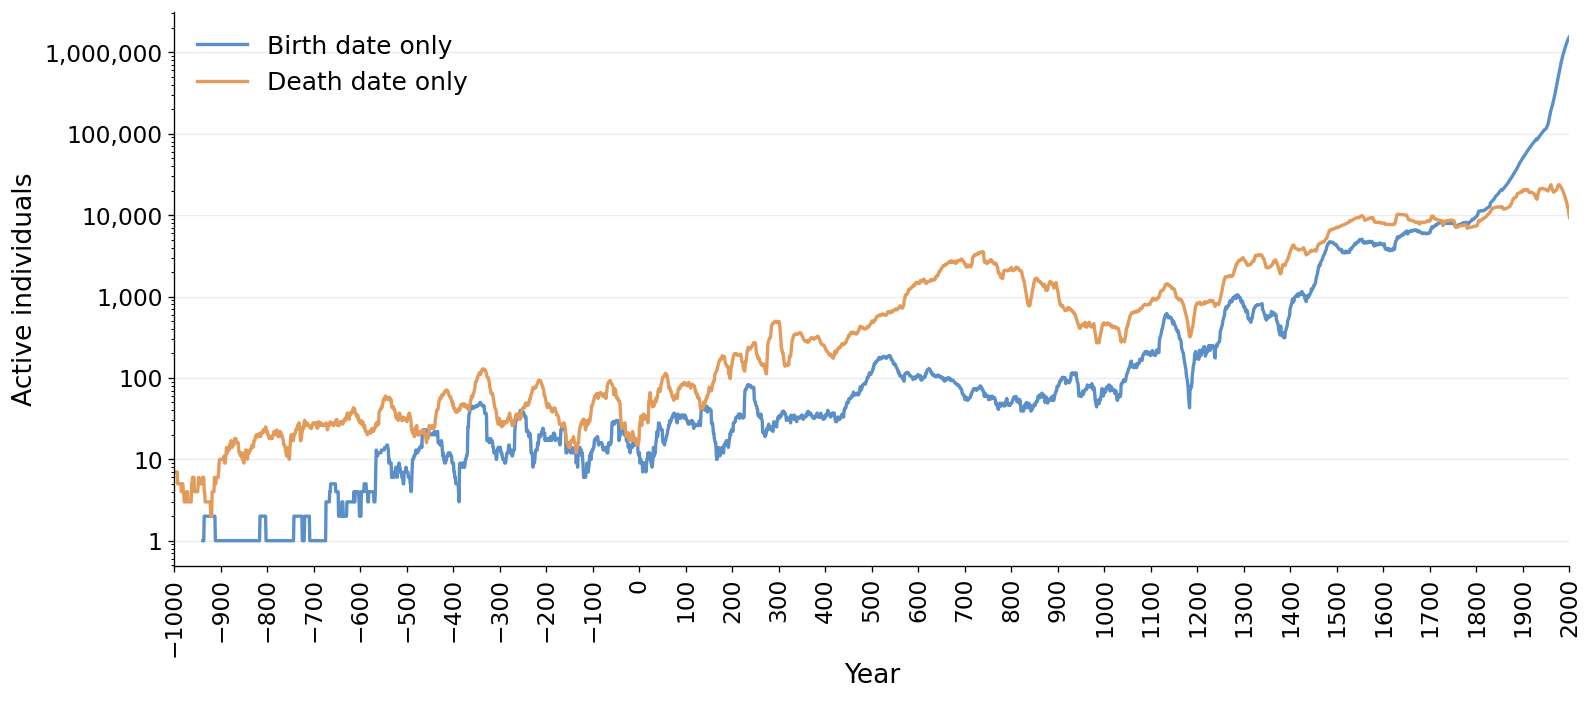

In [6]:
plot_series(active, 'individuals', 'Active individuals', THOUSANDS)

### Figure 2: Share of each group's active years, before 1900
The 1900s are dropped, because most people born then with no death date are still alive. Each series sums to 100% over the years shown, so the two shapes can be compared. Log scale.

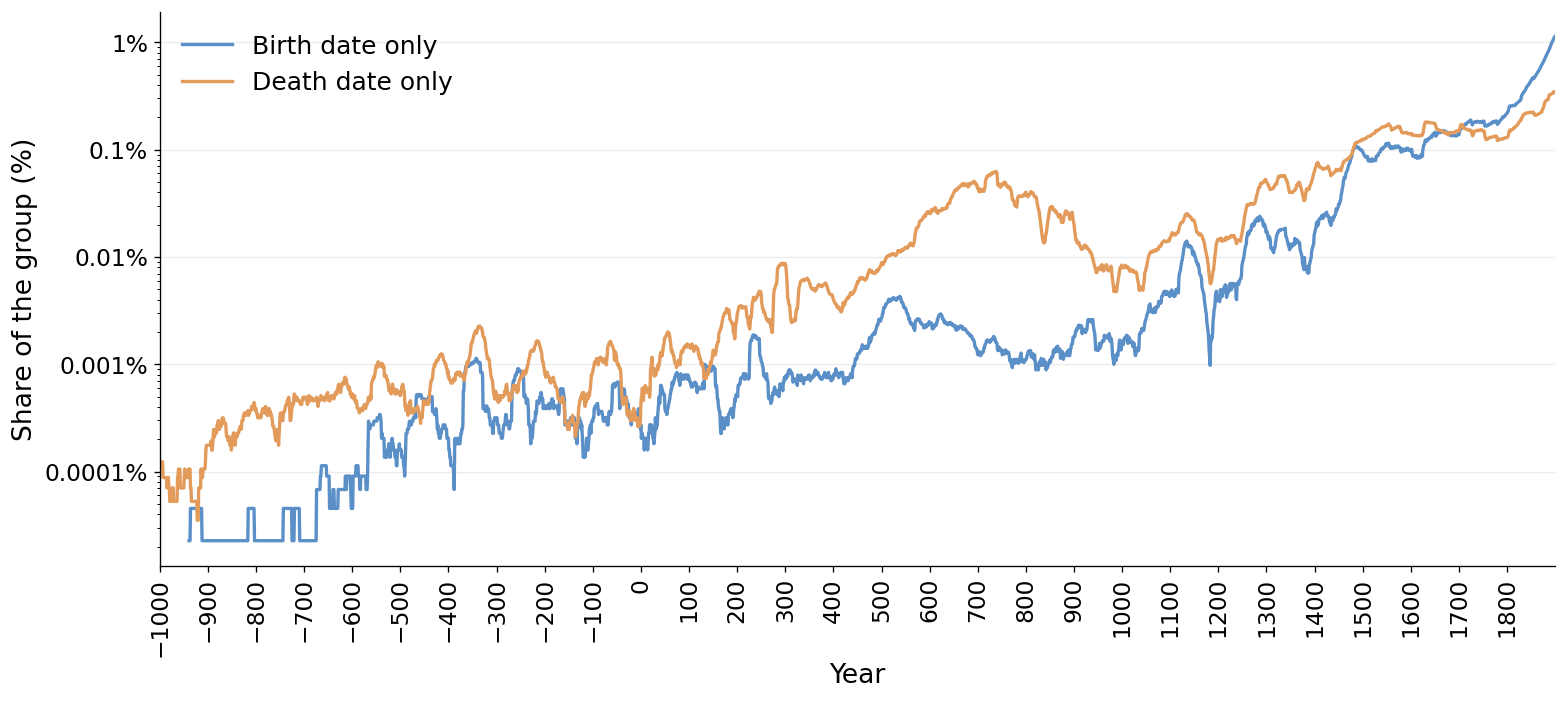

In [7]:
plot_series(before_cutoff, 'share', 'Share of the group (%)', SHARE)